# Прогноз прочности бетона на сжатие

### 1. Загрузка и проверка данных

В таблице семь дозировок в кг/м^3, возраст в днях и прочность в МПа

В столбцах с добавками ноль означает, что в этой смеси добавку не использовали

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Путь работает из папки Course и из корня репозитория
file = Path("concrete_strength.csv")
if not file.exists():
    file = Path("Course") / file

df = pd.read_csv(file)
print("Строк и столбцов", df.shape)
display(df.head())

Строк и столбцов (1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.296075


In [2]:
print("Пропуски по столбцам")
display(df.isna().sum())

print("Полных дубликатов", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
display(df.describe().round(2))

Пропуски по столбцам


cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_aggregate    0
fine_aggregate      0
age                 0
strength_mpa        0
dtype: int64

Полных дубликатов 25


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength_mpa
count,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00
mean,278.63,72.04,55.54,182.07,6.03,974.38,772.69,45.86,35.25
std,104.35,86.17,64.21,21.34,5.92,77.58,80.34,63.73,16.28
min,102.00,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,190.68,0.00,0.00,166.61,0.00,932.00,724.30,7.00,23.52
50%,265.00,20.00,0.00,185.70,6.10,968.00,780.00,28.00,33.80
75%,349.00,142.50,118.27,192.94,10.00,1031.00,822.20,56.00,44.87
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


### 2. Связь между составом и прочностью

Сначала посмотрим, какие признаки сильнее связаны с прочностью

Затем посчитаем среднюю прочность для разных возрастов и дозировок цемента

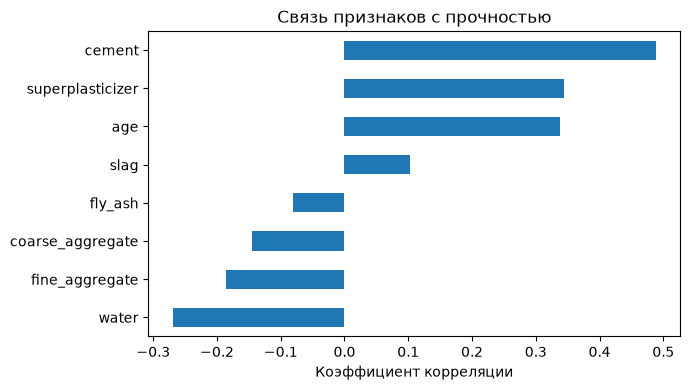

In [3]:
# Чем ближе число к 1 или -1, тем сильнее линейная связь
correlation = df.corr()["strength_mpa"].drop("strength_mpa").sort_values()
correlation.plot.barh(figsize=(7, 4))
plt.title("Связь признаков с прочностью")
plt.xlabel("Коэффициент корреляции")
plt.tight_layout()
plt.show()

In [4]:
age_group = pd.cut(df["age"], [0, 7, 28, 90, 365])
cement_group = pd.cut(df["cement"], [0, 200, 300, 400, 600], right=False)

summary = df.pivot_table(
    values="strength_mpa", index=age_group, columns=cement_group,
    aggfunc="mean", observed=False,
)
summary.index.name = "Возраст, дни"
summary.columns.name = "Цемент, кг/м^3"
display(summary.round(2))

"Цемент, кг/м^3","[0, 200)","[200, 300)","[300, 400)","[400, 600)"
"Возраст, дни",,,,
"(0, 7]",11.24,16.31,25.48,38.00
"(7, 28]",26.29,34.68,41.77,55.95
"(28, 90]",39.06,42.96,50.83,60.53
"(90, 365]",45.42,46.59,48.08,59.00


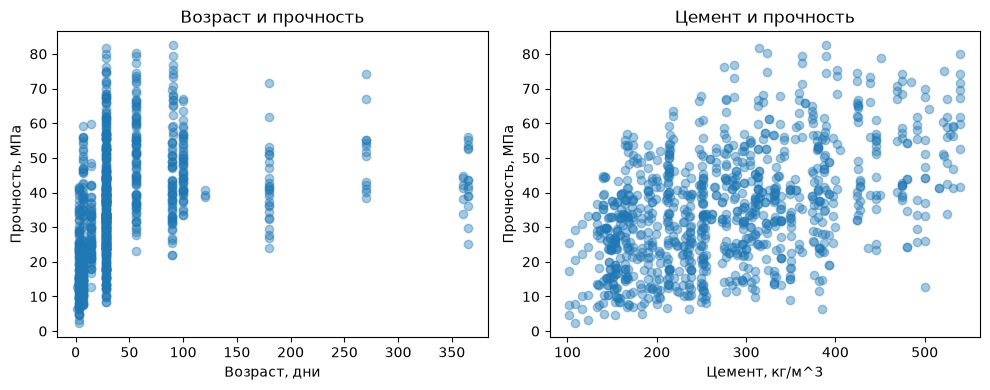

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(df["age"], df["strength_mpa"], alpha=0.4)
axes[0].set(xlabel="Возраст, дни", ylabel="Прочность, МПа", title="Возраст и прочность")

axes[1].scatter(df["cement"], df["strength_mpa"], alpha=0.4)
axes[1].set(xlabel="Цемент, кг/м^3", ylabel="Прочность, МПа", title="Цемент и прочность")

plt.tight_layout()
plt.show()

### 3. Деление данных

Около 80% рецептур используем для обучения, остальные для проверки

Измерения одного состава в разные дни держим вместе

Так в тесте будут рецептуры, которых модели раньше не видели

In [6]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score

X = df.drop(columns="strength_mpa")
y = df["strength_mpa"]

# Присваиваем одинаковому составу один номер, даже если возраст отличается
recipe_columns = X.columns.drop("age").tolist()
recipes = df.groupby(recipe_columns).ngroup()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train, test = next(splitter.split(X, y, groups=recipes))

X_train, X_test = X.iloc[train], X.iloc[test]
y_train, y_test = y.iloc[train], y.iloc[test]

print("Строк для обучения", len(train))
print("Строк для проверки", len(test))
print("Рецептур в тесте", recipes.iloc[test].nunique())

Строк для обучения 810
Строк для проверки 195
Рецептур в тесте 86


### 4. Обучение моделей

Проверяем модели на пяти частях обучающих данных

Выбираем ту, у которой меньше средняя ошибка, а прогноз по среднему берём для сравнения

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Приводим входные числа к одному масштабу для нейросети
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(32, 16), learning_rate_init=0.005,
        tol=0.01, max_iter=2500, random_state=42,
    )),
])

models = {
    "Линейная регрессия": LinearRegression(),
    "Нейросеть": mlp,
    "Дерево решений": DecisionTreeRegressor(max_depth=7, min_samples_leaf=4, random_state=42),
    "Случайный лес": RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=42),
    "Средний прогноз": DummyRegressor(strategy="mean"),
}

# меняем знак MAE
cv = GroupKFold(n_splits=5)
cv_errors = {}
for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, groups=recipes.iloc[train],
        cv=cv, scoring="neg_mean_absolute_error", error_score="raise",
    )
    cv_errors[name] = -scores.mean()

cv_table = pd.Series(cv_errors, name="Средняя MAE, МПа").sort_values()
best_name = cv_table.index[0]
display(cv_table.round(3))
print("Выбранная модель -", best_name)

Случайный лес          4.662
Нейросеть              5.267
Дерево решений         6.629
Линейная регрессия     8.433
Средний прогноз       13.217
Name: Средняя MAE, МПа, dtype: float64

Выбранная модель - Случайный лес


### 5. Проверка на тестовых данных

MAE показывает средний промах в МПа, MAPE показывает ошибку в процентах

RMSE сильнее реагирует на большие промахи

Для R^2 лучше значение ближе к единице

In [8]:
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error,
    mean_squared_error, root_mean_squared_error, r2_score,
)

results = []
predictions = {}

# Каждую модель обучаем на всех обучающих строках и проверяем на одном тесте
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    predictions[name] = prediction
    results.append({
        "Модель": name,
        "MAE, МПа": mean_absolute_error(y_test, prediction),
        "MSE, МПа^2": mean_squared_error(y_test, prediction),
        "RMSE, МПа": root_mean_squared_error(y_test, prediction),
        "MAPE, %": mean_absolute_percentage_error(y_test, prediction) * 100,
        "R^2": r2_score(y_test, prediction),
    })

result_table = pd.DataFrame(results).set_index("Модель")
display(result_table.round(3))

,"MAE, МПа","MSE, МПа^2","RMSE, МПа","MAPE, %",R^2
Модель,,,,,
Линейная регрессия,7.516,91.869,9.585,28.716,0.648
Нейросеть,4.425,32.860,5.732,15.658,0.874
Дерево решений,6.116,63.644,7.978,19.217,0.756
Случайный лес,4.371,32.112,5.667,14.541,0.877
Средний прогноз,12.921,261.084,16.158,58.016,-0.000


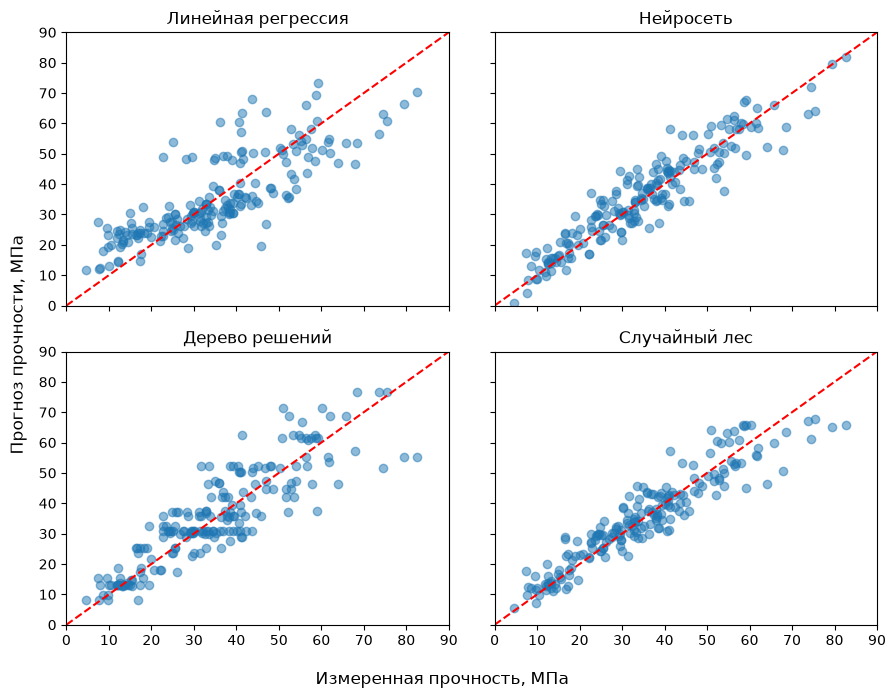

In [9]:
# Чем ближе точка к линии, тем точнее прогноз для этого образца
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
limit = [0, 90]

for ax, name in zip(axes.flat, list(models)[:4]):
    ax.scatter(y_test, predictions[name], alpha=0.5)
    ax.plot(limit, limit, "r--")
    ax.set(title=name, xlim=limit, ylim=limit)

fig.supxlabel("Измеренная прочность, МПа")
fig.supylabel("Прогноз прочности, МПа")
plt.tight_layout()
fig.subplots_adjust(wspace=0.12)
plt.show()

### 6. Важность признаков и пример прогноза

Посмотрим, какие признаки сильнее помогли случайному лесу уменьшить ошибку при обучении

Затем возьмём один состав и сравним прогноз прочности в 7, 28 и 90 дней

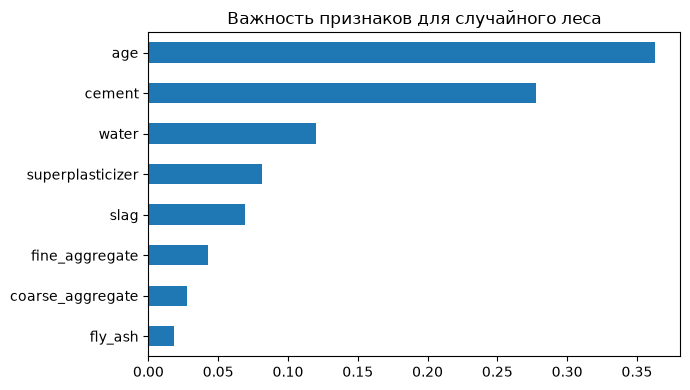

In [10]:
forest = models["Случайный лес"]
importance = pd.Series(forest.feature_importances_, index=X.columns)
importance.sort_values().plot.barh(figsize=(7, 4))
plt.title("Важность признаков для случайного леса")
plt.tight_layout()
plt.show()

In [11]:
# Сначала семь дозировок в кг/м^3, затем возраст в днях
recipe = [326, 90, 75, 182, 6, 1000, 770]
example = pd.DataFrame([recipe + [age] for age in [7, 28, 90]], columns=X.columns)

example["Прогноз, МПа"] = models[best_name].predict(example).round(2)
display(example[["age", "Прогноз, МПа"]].rename(columns={"age": "Возраст, дни"}))

mae = result_table.loc[best_name, "MAE, МПа"]
r2 = result_table.loc[best_name, "R^2"]
print(f"{best_name} на тесте, MAE = {mae:.2f} МПа, R^2 = {r2:.3f}")

,"Возраст, дни","Прогноз, МПа"
0,7,21.77
1,28,46.52
2,90,48.12


Случайный лес на тесте, MAE = 4.37 МПа, R^2 = 0.877
